**WandB training curves without manual CSV download**

Run `wandb login` once before using this notebook.

In [1]:
from pathlib import Path
import os
import sys

FIGURES_DIR = Path.cwd()
if FIGURES_DIR.name != "figures" and (FIGURES_DIR / "figures").exists():
    FIGURES_DIR = FIGURES_DIR / "figures"
os.chdir(FIGURES_DIR)
sys.path.insert(0, str(FIGURES_DIR))

import importlib
import wandb_training_curves
importlib.reload(wandb_training_curves)

from wandb_training_curves import (
    DEFAULT_ENTITY,
    build_plot_config,
    fetch_wandb_training_curves,
    plot,
    print_performance_table,
    plot_final_distribution,
    plot_horizontal_legend
)

ENTITY = DEFAULT_ENTITY

SMAX_PLOT_LEGEND_SHOWN = False

def show_smax_plot_legend_once(plot_config, figsize=(5, 0.4)):
    global SMAX_PLOT_LEGEND_SHOWN
    if SMAX_PLOT_LEGEND_SHOWN:
        return
    plot_horizontal_legend(
        plot_config,
        figsize=figsize,
        ncol=len(plot_config),
    )
    SMAX_PLOT_LEGEND_SHOWN = True



**SMAX**

Use `condition=None` for vanilla SMAX runs. Vanilla is fetched with the map token included and any run containing `tar_w` excluded, so target-window runs are not mixed into the vanilla plot.

In [2]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

SMAX_MAP_SCENARIOS = [
    # {
    #     "map": "3m",
    #     "label": "3m",
    #     "cases": [
    #         {"level": "Vanilla", "condition": None, "label": "vanilla"},
    #         {"level": "Hard", "condition": "tar_w=2", "label": "tar_w=2"},
    #     ],
    # },
    # {
    #     "map": "2s3z",
    #     "label": "2s3z",
    #     "cases": [
    #         {"level": "Vanilla", "condition": None, "label": "vanilla"},
    #         {"level": "Medium", "condition": "tar_w=4", "label": "tar_w=4"},
    #         {"level": "Hard", "condition": "tar_w=3", "label": "tar_w=3"},
    #     ],
    # },
    # {
    #     "map": "3s5z",
    #     "label": "3s5z",
    #     "cases": [
    #         {"level": "Vanilla", "condition": None, "label": "vanilla"},
    #         {"level": "Hard", "condition": "tar_w=6", "label": "tar_w=6"},
    #     ],
    # },
    {
        "map": "6h_vs_8z",
        "label": "6h_vs_8z",
        "cases": [
            {"level": "Vanilla", "condition": None, "label": "vanilla"},
            {"level": "Hard", "condition": "tar_w=6", "label": "tar_w=6"},
        ],
    },
    # {
    #     "map": "smacv2_5_units",
    #     "label": "SMACv2 5 Units",
    #     "cases": [
    #         {"level": "Vanilla", "condition": None, "label": "vanilla"},
    #         {"level": "Medium", "condition": "tar_w=4", "label": "tar_w=4"},
    #         {"level": "Hard", "condition": "tar_w=3", "label": "tar_w=3"},
    #     ],
    # },
    # {
    #     "map": "smacv2_10_units",
    #     "label": "SMACv2 10 Units",
    #     "cases": [
    #         {"level": "Vanilla", "condition": None, "label": "vanilla"},
    #         {"level": "Medium", "condition": "tar_w=8", "label": "tar_w=8"},
    #         {"level": "Hard", "condition": "tar_w=6", "label": "tar_w=6"},
    #     ],
    # },
]


=== SMAX: 6h_vs_8z, Vanilla (vanilla) ===
[project] pci-marl-smax-jax
[collect] mappo      jax_mappo_smax_6h_vs_8z_seed42 (801 points)
[collect] mappo      jax_mappo_smax_6h_vs_8z_seed1 (801 points)
[collect] mappo      jax_mappo_smax_6h_vs_8z_seed2 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_lr1e-3_proxyX_seed42 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_lr1e-3_proxyX_seed42 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_lr1e-3_proxyX_seed1 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_lr1e-3_proxyX_seed1 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_lr1e-3_proxyX_seed2 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_lr1e-3_proxyX_seed2 (801 points)
[collect] ippo       jax_ippo_smax_6h_vs_8z_lr1e-3_seed2 (801 points)
[collect] ippo       jax_ippo_smax_6h_vs_8z_lr1e-3_GD4_seed42 (801 points)
[collect] ippo       jax_ippo_smax_6h_vs_8z_lr1e-3_GD4_seed1 (801 points)
[write] wandb_cache/SMAX_6

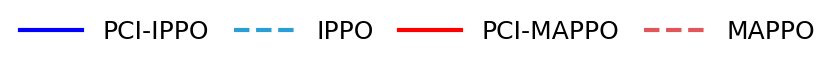


=== SMAX: 6h_vs_8z, Hard (tar_w=6) ===
[project] pci-marl-smax-jax
[collect] mappo      jax_mappo_smax_6h_vs_8z_tar_w=6_seed42 (801 points)
[collect] mappo      jax_mappo_smax_6h_vs_8z_tar_w=6_seed1 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed42 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed42 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed1 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed1 (801 points)
[collect] pci_mappo  jax_pci_mappo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed2 (801 points)
[collect] pci_ippo   jax_pci_ippo_smax_6h_vs_8z_tar_w=6_lr1e-3_proxyX_seed2 (801 points)
[collect] mappo      jax_mappo_smax_6h_vs_8z_tar_w=6_seed2 (801 points)
[collect] ippo       jax_ippo_smax_6h_vs_8z_tar_w=6_lre2e-3_seed42 (801 points)
[collect] ippo       jax_ippo_smax_6h_vs_8z_tar_w=6_lre2e-3_seed2 (801 points)
[collect] ippo   

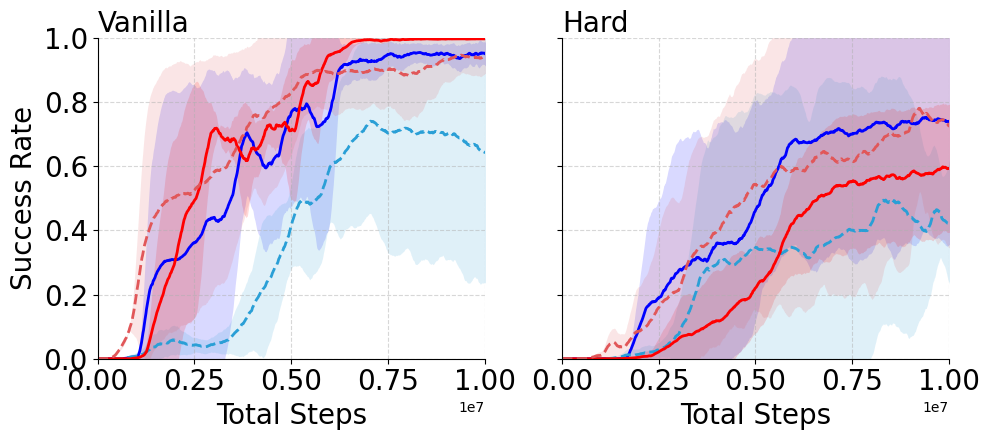

In [3]:
WINDOW = 20
SMAX_FIGSIZE = (5, 4.5)
SMAX_FONT_SIZE = 20
SMAX_XLIM = (0, 1e7)
SMAX_YLIM = (0, 1)
SMAX_PLOT_LEGEND_SHOWN = False

# Mean curve with optional 1 std shading across seeds.
SMAX_SHOW_STD_SHADING = True
SMAX_STD_SHADING_ALPHA = 0.15


def smax_cache_dir(smax_map, label):
    filter_name = "_".join(str(part).replace("=", "") for part in (smax_map, label) if part)
    return Path("wandb_cache") / f"SMAX_{filter_name}"


def fetch_and_build_smax_config(case):
    smax_map = case["map"]
    condition = case["condition"]
    label = case.get("label") or ("vanilla" if condition is None else condition)
    is_vanilla = condition is None

    smax_filter = [smax_map] if is_vanilla else [smax_map, condition]
    smax_filter = [term for term in smax_filter if term]
    smax_exclude = ["tar_w"] if is_vanilla else []
    output_dir = smax_cache_dir(smax_map, label)

    print(f"\n=== SMAX: {smax_map}, {case['level']} ({label}) ===")
    fetch_wandb_training_curves(
        preset="smax",
        entity=ENTITY,
        output_dir=output_dir,
        state="finished",
        contains=smax_filter,
        exclude_contains=smax_exclude,
    )
    return build_plot_config("smax", output_dir)


def matching_success_rate_columns(df, entry):
    keyword = entry.get("keyword", "success_rate")
    exclude = entry.get("exclude", None)
    clean_kw = keyword.lower().replace("_", "").replace("-", "")
    cols = []
    for col in df.columns:
        col_lower = col.lower()
        if "success_rate" not in col_lower:
            continue
        clean_col = col_lower.replace("_", "").replace("-", "")
        if clean_kw not in clean_col:
            continue
        if "MIN" in col or "MAX" in col or "_step" in col:
            continue
        if exclude and exclude.lower() in col_lower:
            continue
        cols.append(col)
    return cols


def plot_smax_config_on_axis(
    ax,
    plot_config,
    window_size=WINDOW,
    show_std_shading=SMAX_SHOW_STD_SHADING,
):
    for entry in plot_config:
        try:
            df = pd.read_csv(entry["path"])
        except FileNotFoundError:
            print(f"[WARN] File not found: {entry['path']}")
            continue

        cols = matching_success_rate_columns(df, entry)
        if not cols:
            print(f"[WARN] No matching columns for {entry['label']} in {entry['path']}")
            continue

        x = df["total_steps"]
        seed_curves = df[cols].rolling(window=window_size, min_periods=1).mean()
        y_mean = seed_curves.mean(axis=1)
        ax.plot(
            x,
            y_mean,
            label=entry["label"],
            color=entry["color"],
            linestyle=entry.get("linestyle", "-"),
            linewidth=entry.get("linewidth", 2),
        )

        if show_std_shading:
            y_std = seed_curves.std(axis=1).rolling(window=max(5, window_size // 4), min_periods=1).mean()
            ax.fill_between(
                x,
                y_mean - y_std,
                y_mean + y_std,
                color=entry["color"],
                alpha=SMAX_STD_SHADING_ALPHA,
                linewidth=0,
            )

    ax.grid(True, linestyle="--", alpha=0.5)
    ax.tick_params(axis="both", labelsize=SMAX_FONT_SIZE)
    ax.set_xlim(*SMAX_XLIM)
    ax.set_ylim(*SMAX_YLIM)
    ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def plot_smax_map_subplot(scenario):
    cases = scenario["cases"]
    fig, axes = plt.subplots(
        1,
        len(cases),
        figsize=(SMAX_FIGSIZE[0] * len(cases), SMAX_FIGSIZE[1]),
        sharey=True,
    )
    if len(cases) == 1:
        axes = [axes]

    for ax, case_spec in zip(axes, cases):
        config_case = {"map": scenario["map"], **case_spec}
        smax_config = fetch_and_build_smax_config(config_case)
        show_smax_plot_legend_once(smax_config)
        plot_smax_config_on_axis(ax, smax_config)
        ax.set_title(case_spec["level"], fontsize=SMAX_FONT_SIZE, loc="left", pad=2)
        ax.set_xlabel("Total Steps", fontsize=SMAX_FONT_SIZE)

    axes[0].set_ylabel("Success Rate", fontsize=SMAX_FONT_SIZE)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


for scenario in SMAX_MAP_SCENARIOS:
    plot_smax_map_subplot(scenario)


**SMAX causal reward during training**


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

SMAX_CAUSAL_DIR = Path("wandb_cache/smax_3m_causal")
SMAX_CAUSAL_FIGSIZE = (6.7, 5.4)
SMAX_CAUSAL_FONT_SIZE = 20
SMAX_CAUSAL_WINDOW = 20

SMAX_CAUSAL_CASES = {
    "target": {
        "label": "Target",
        "metric": "target_attack",
        "suffix": "target",
        "linestyle": "-",
    },
    "nontarget": {
        "label": "Non-target",
        "metric": "non_target_attack",
        "suffix": "nontarget",
        "linestyle": "--",
    },
    "other": {
        "label": "Other",
        "metric": "other_action",
        "suffix": "other",
        "linestyle": ":",
    },
}

SMAX_CAUSAL_MODELS = {
    "ipci": {
        "label": "PCI-IPPO",
        "keyword": "jax_pci_ippo",
        "color": "#0050a4",
        "prefixes": ("ipci", "icpi"),
    },
    "mpci": {
        "label": "PCI-MAPPO",
        "keyword": "jax_pci_mappo",
        "color": "#b00020",
        "prefixes": ("mpci", "mcpi"),
    },
}


def find_smax_causal_csv(model_entry, case_entry, base_dir=SMAX_CAUSAL_DIR):
    for prefix in model_entry["prefixes"]:
        path = base_dir / f"{prefix}_3m_{case_entry['suffix']}.csv"
        if path.exists():
            return path

    matches = []
    for prefix in model_entry["prefixes"]:
        matches.extend(base_dir.glob(f"{prefix}*{case_entry['suffix']}*.csv"))
    if not matches:
        raise FileNotFoundError(
            f"No SMAX causal CSV for {model_entry['label']} / {case_entry['label']} in {base_dir}"
        )
    return sorted(matches)[0]


def read_smax_causal_series(csv_path, model_entry, case_entry):
    df = pd.read_csv(csv_path)
    metric_cols = [
        col for col in df.columns
        if (
            model_entry["keyword"] in col
            and case_entry["metric"] in col
            and col.endswith("_mean")
            and not col.endswith("__MIN")
            and not col.endswith("__MAX")
        )
    ]
    if not metric_cols:
        raise ValueError(f"No metric columns matching {case_entry['metric']} in {csv_path}")

    series = []
    for metric_col in metric_cols:
        # wandb's `_step` is a row index here; `total_steps` is the training x-axis.
        step_col = "total_steps"
        subset = df[[step_col, metric_col]].dropna().rename(
            columns={step_col: "step", metric_col: "value"}
        )
        if subset.empty:
            continue
        subset["step"] = pd.to_numeric(subset["step"], errors="coerce")
        subset["value"] = pd.to_numeric(subset["value"], errors="coerce")
        subset = subset.dropna().drop_duplicates("step").sort_values("step")
        if not subset.empty:
            series.append(subset)

    if not series:
        raise ValueError(f"All matching columns were empty in {csv_path}")
    return series


def smooth_series(values, window_size=SMAX_CAUSAL_WINDOW):
    if window_size <= 1:
        return values
    return values.rolling(window=window_size, min_periods=1, center=True).mean()


def aggregate_smax_causal(series, window_size=SMAX_CAUSAL_WINDOW):
    x_values = np.array(sorted(set().union(*(set(s["step"]) for s in series))))
    aligned = []
    for one_series in series:
        y = np.interp(x_values, one_series["step"].to_numpy(), one_series["value"].to_numpy())
        aligned.append(smooth_series(pd.Series(y), window_size).to_numpy())
    values = np.vstack(aligned)
    return x_values, values.mean(axis=0), values.std(axis=0)


def build_smax_causal_config(model="ipci", base_dir=SMAX_CAUSAL_DIR):
    model_entry = SMAX_CAUSAL_MODELS[model]
    entries = []
    for case_key, case_entry in SMAX_CAUSAL_CASES.items():
        path = find_smax_causal_csv(model_entry, case_entry, base_dir=base_dir)
        series = read_smax_causal_series(path, model_entry, case_entry)
        entries.append({
            "label": case_entry["label"],
            "linestyle": case_entry["linestyle"],
            "color": model_entry["color"],
            "series": series,
            "path": path,
        })
    return {
        "model_label": model_entry["label"],
        "color": model_entry["color"],
        "entries": entries,
    }


def plot_smax_causal_reward(
    config,
    window_size=SMAX_CAUSAL_WINDOW,
    figsize=SMAX_CAUSAL_FIGSIZE,
    xlim=(0, 1e7),
    ylim=None,
    show=True,
):
    with plt.rc_context({
        "font.size": SMAX_CAUSAL_FONT_SIZE,
        "axes.labelsize": SMAX_CAUSAL_FONT_SIZE,
        "xtick.labelsize": SMAX_CAUSAL_FONT_SIZE,
        "ytick.labelsize": SMAX_CAUSAL_FONT_SIZE,
        "legend.fontsize": SMAX_CAUSAL_FONT_SIZE,
    }):
        fig, ax = plt.subplots(figsize=figsize)
        for entry in config["entries"]:
            x, y_mean, _ = aggregate_smax_causal(entry["series"], window_size=window_size)
            ax.plot(
                x,
                y_mean,
                color=entry["color"],
                linestyle=entry["linestyle"],
                linewidth=2,
            )

        ax.set_xlabel("Total Steps")
        ax.set_ylabel("Credit-Aligned Reward")
        ax.set_xlim(*xlim)
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
        ax.grid(alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        fig.tight_layout()
        if show:
            display(fig)
        return fig, ax


def plot_smax_causal_legend(figsize=(6.7, 0.1), color="black", ncol=3):
    handles = [
        Line2D([0], [0], color=color, linestyle=entry["linestyle"], linewidth=2, label=entry["label"])
        for entry in SMAX_CAUSAL_CASES.values()
    ]
    with plt.rc_context({"legend.fontsize": SMAX_CAUSAL_FONT_SIZE}):
        fig, ax = plt.subplots(figsize=figsize)
        ax.axis("off")
        ax.legend(
            handles=handles,
            loc="center",
            ncol=ncol,
            frameon=False,
            handlelength=2.6,
            columnspacing=1.0,
            handletextpad=0.4,
            borderaxespad=0.0,
        )
        fig.tight_layout(pad=0)
        display(fig)
        return fig


/tmp/ipykernel_3711941/1245972481.py:195: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(pad=0)


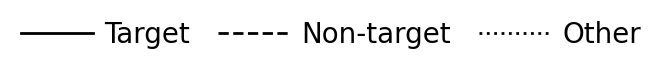

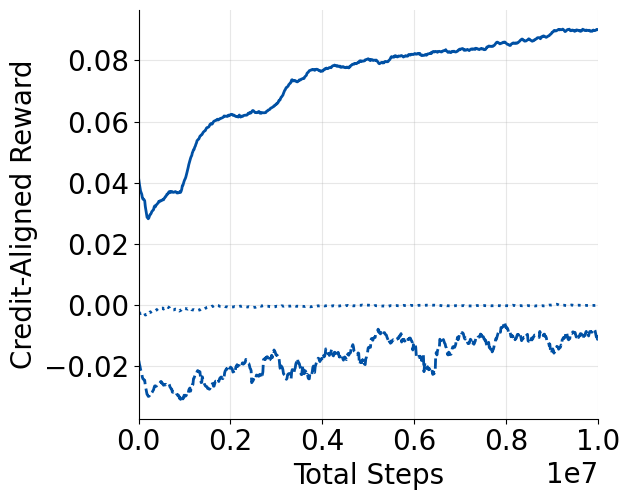

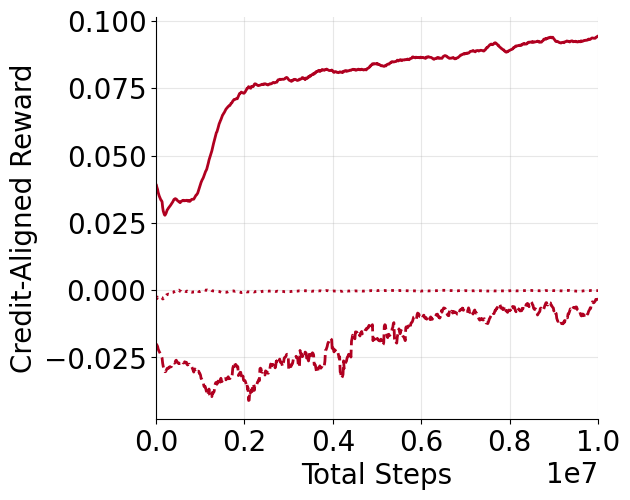

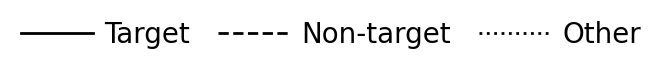

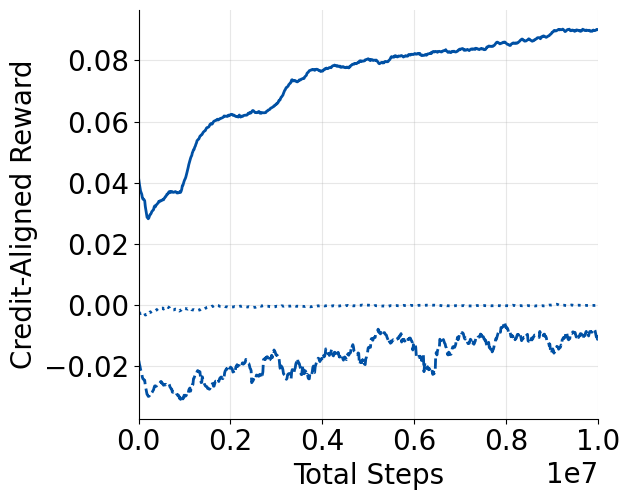

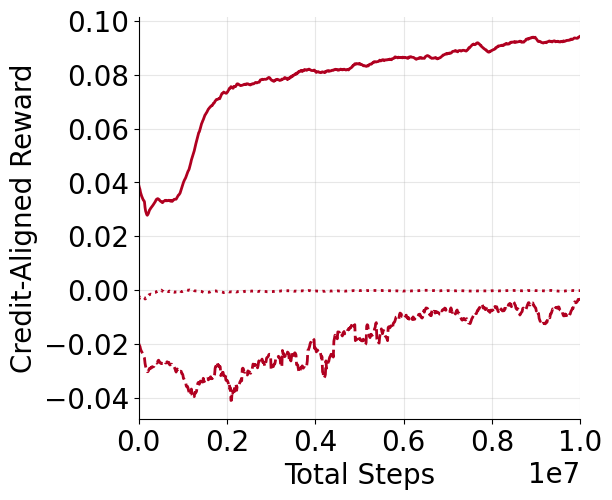

In [5]:
plot_smax_causal_legend(figsize=(6.7, 0.1))

for model in ("ipci", "mpci"):
    smax_causal_config = build_smax_causal_config(model=model)
    plot_smax_causal_reward(
        smax_causal_config,
        window_size=SMAX_CAUSAL_WINDOW,
        figsize=SMAX_CAUSAL_FIGSIZE,
        xlim=(0, 1e7),
    )


**CLI examples**

In [6]:
# !python wandb_training_curves.py --preset sh --plot --save-png sh_training_curve.png
# !python wandb_training_curves.py --preset sh-noise --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset sh --name-suffix _noise0.1 --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset smax --list-runs --contains 2s3z
# !python wandb_training_curves.py --preset smax --contains 2s3z tar_w=4 --plot --save-png smax_2s3z_tarw4.png